# PCA

In [1]:
# import data science libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# import advanced plot drawing library
import seaborn as sns
# import data science library with added geographic functions
import geopandas as gpd
# useful to calculate the Ordinary Least Square linear regression
import statsmodels
# useful to get fast distance calculation,
# see https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.BallTree.html
from sklearn.neighbors import BallTree, KDTree
# useful to access functions like median, mean or std
from scipy import stats
# useful to get map background but hard to install...
# If not available REMOVE this
import contextily as cx
sns.set_style("white")

## 1 – Real Estate dataset: Anjuke

This dataset has been created in UTSEUS in 2017. The souce page for it is (anjuke)[https://shanghai.anjuke.com/sale]

This dataset is given to you as a (pickle)[https://docs.python.org/3/library/pickle.html] which can be used directly as a variable.
The format is called pickle, it is like a zip but can only be read in python. 

In [2]:
# change path to your PATH. if the file can be seen on the left you can just put the file name directly
real_estate_file = 'utseus-anjuke-real-estate.pk'
anjuke = pd.read_pickle(real_estate_file)

the pickle is just a list of list. The first item is the columns name, the rest is the data
The dataframe need to have the data first, and the name of the columns separately. 
We use (list comprehension)[https://docs.python.org/3/tutorial/introduction.html#lists] to achieve this.

In [3]:
anjuke_df = pd.DataFrame(anjuke[1:], columns=anjuke[0])


Use .info or .describe functions to get a better idea of the dataset

In [5]:
anjuke_df.info()
# the info reveal everything is object, there are no numbers

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 467029 entries, 0 to 467028
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   id              467029 non-null  object
 1   address         467029 non-null  object
 2   longitude       467029 non-null  object
 3   latitude        467029 non-null  object
 4   bedroom         467029 non-null  object
 5   room            467029 non-null  object
 6   surface         467029 non-null  object
 7   price           467029 non-null  object
 8   onesquaremeter  467029 non-null  object
 9   tags            467029 non-null  object
 10  district        467029 non-null  object
 11  neighborhood    467029 non-null  object
 12  done            467029 non-null  object
dtypes: object(13)
memory usage: 46.3+ MB


all of the field we see in the columns are object and have not been correctly imported as numbers. Consequently we cannot calculate with these columns as they are considered as words. We need numbers. To convert from words to numbers we use a special function from python. 

All numeric columns shall transformed into floats using pandas (to_numeric)[https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.to_numeric.html] function.

In [6]:
numeric_columns = ['longitude', 'latitude', 'bedroom', 'room', 'surface','price', 'onesquaremeter']
# put the function in the following line
anjuke_df[numeric_columns] = anjuke_df[numeric_columns].apply(pd.to_numeric)

now we can have some numbers that could not be converted. the rows containing these undefined values need to be dropped. 

Do that using the function (dropna)[https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.dropna.html]

In [38]:

anjuke_df = anjuke_df.dropna()


check if the colums have been successfully changed.

You should observe that we 'lost' 3962 records that were incomplete with a non numeric data

use .info() again

In [39]:
anjuke_df.info()# write the call to .info here

<class 'pandas.core.frame.DataFrame'>
Index: 463067 entries, 0 to 467028
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   id              463067 non-null  object  
 1   address         463067 non-null  category
 2   longitude       463067 non-null  float64 
 3   latitude        463067 non-null  float64 
 4   bedroom         463067 non-null  int64   
 5   room            463067 non-null  int64   
 6   surface         463067 non-null  float64 
 7   price           463067 non-null  float64 
 8   onesquaremeter  463067 non-null  float64 
 9   tags            463067 non-null  category
 10  district        463067 non-null  category
 11  neighborhood    463067 non-null  category
 12  done            463067 non-null  category
dtypes: category(5), float64(5), int64(2), object(1)
memory usage: 47.6+ MB


Time to tranform the dataset into a geodataframe now so we can perform geographic operations

Right now we just have GPS has numbers in columns. This is not ready to be used on a map. For that we need to convert it into a geographic object that can be a point, a line or a polygon. In our case it is a point 

In [8]:
anjuke_gdf = gpd.GeoDataFrame(
anjuke_df,geometry=gpd.points_from_xy(anjuke_df.longitude, anjuke_df.latitude),crs=4326)

plot the data on a map using the plot function with the following properties
plot(markersize=0.5, color='black', figsize=(10,10))

<Axes: >

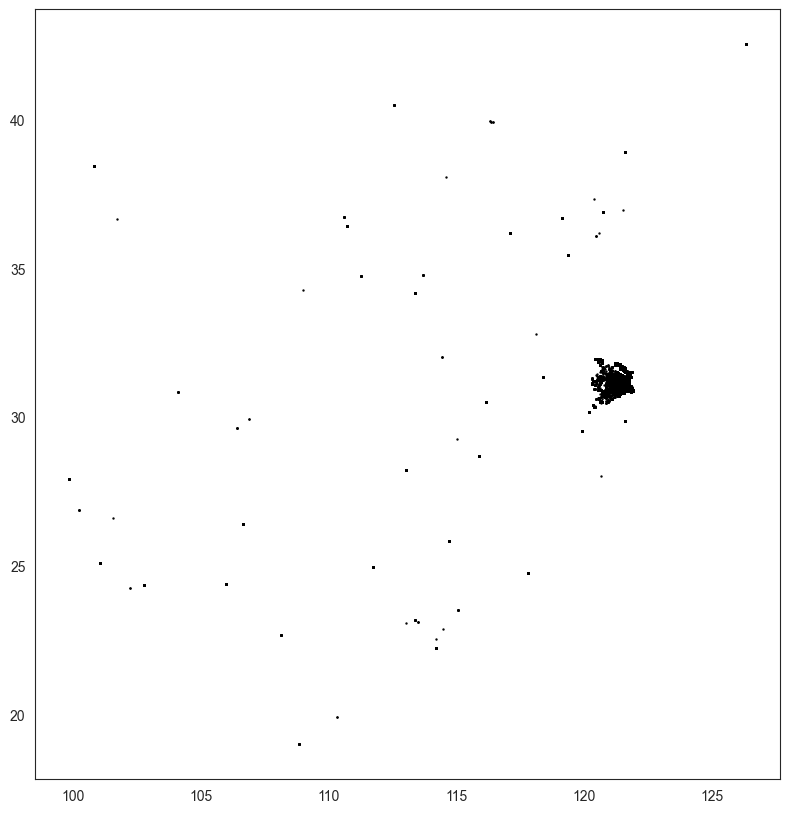

In [9]:
anjuke_gdf.plot(markersize=0.5, color='black', figsize=(10,10))

We observe that data are not only in Shanghai. 

Write HERE why you think it is like this ? 

The data might include locations outside Shanghai due to incorrect GPS entries, listings from other cities, or errors during data collection.


To have an idea of the spread of data, we can print or we can check the boundaries using the property (total_bounds)[https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoSeries.total_bounds.html]

In [10]:
# use the property and print the result
anjuke_gdf.total_bounds


array([ 99.82410591,  18.99369628, 126.33039253,  42.54940926])

In both cases, it seems there are data outside Shanghai.

To limit it we have two options:
- one is to use _cx_ to specify a bounding box
- another one is to provide a shape for the area and filter points within

### Lets start with bounding box

to find the bounding box you can use GIS or search for it. we can use [bboxfinder.com](http://bboxfinder.com/)  for example

In [11]:
print(f'before {len(anjuke_gdf)}')
west = 121.10157
east = 121.804611
north = 31.514999
south = 30.975
xmin, ymin, xmax, ymax = (west,south,east,north)
anjuke_filterbb_gdf = anjuke_gdf.cx[xmin:xmax, ymin:ymax]
print(f'after {len(anjuke_filterbb_gdf)}')

before 467029
after 392383


we check if the latitude or longitude we have is in GCJ format of GPS format by looking at the huangpu river

## 2 – POI dataset: Gaode

This dataset has been bought from Gaode for SHU Cendus institute in 2020. We choose the POI from 2017 to be consistant with the anjuke dataset also from 2017 

In [102]:
poi_df = pd.read_csv('shanghaiPOI2017.csv',delimiter=';', decimal=',',low_memory=False)

In [103]:
poi_df.columns

Index(['Unnamed: 0', 'ID', 'POIID', 'GCJX', 'GCJY', 'NAME', 'ADD', 'TEL',
       'TYPE', 'AREAID', 'IDKEY', 'GPSX', 'GPSY', 'TYPE1', 'TYPE2', 'TYPE3',
       'TYPE4', 'TYPE5', 'TYPE3.1', 'TYPE3.2', 'TYPE3.3', 'TYPE1.N', 'TYPE2.N',
       'TYPE3.N', 'TYPE3.1.N', 'TYPECODE', 'GBCODE'],
      dtype='object')

In [104]:
# write the function to create the geodataframe here usin gthe same method as before
poi_gdf = gpd.GeoDataFrame(
poi_df,
geometry=gpd.points_from_xy(poi_df.GPSX, poi_df.GPSY), crs=4326)

In [105]:
poi_gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 28 columns):
 #   Column      Non-Null Count    Dtype   
---  ------      --------------    -----   
 0   Unnamed: 0  1048575 non-null  int64   
 1   ID          1048575 non-null  int64   
 2   POIID       1048575 non-null  object  
 3   GCJX        1048575 non-null  float64 
 4   GCJY        1048575 non-null  float64 
 5   NAME        1048575 non-null  object  
 6   ADD         1035459 non-null  object  
 7   TEL         248819 non-null   object  
 8   TYPE        1048575 non-null  object  
 9   AREAID      1048575 non-null  int64   
 10  IDKEY       1048575 non-null  float64 
 11  GPSX        1048575 non-null  float64 
 12  GPSY        1048575 non-null  float64 
 13  TYPE1       1048575 non-null  object  
 14  TYPE2       1048575 non-null  object  
 15  TYPE3       1048575 non-null  object  
 16  TYPE4       11141 non-null    object  
 17  TYPE5       11141 non-null    object  

In [106]:
 poi_gdf.to_crs(4576, inplace=True)

In [107]:
anjuke_filterbb_gdf.to_crs(4576, inplace=True)


In [108]:
gbcodes= poi_gdf.GBCODE.unique()

In [109]:
gbcodes

array([990000., 209900., 201203., 201200., 201202., 201204., 200301.,
       190600., 130900., 110100., 110503., 201201., 200501., 200504.,
       200402., 200401., 200100., 200104., 200102., 200601., 201401.,
       230100., 170000., 200201., 210501., 219900., 201402., 129900.,
       160303., 160300., 220100., 220301., 160600., 110500., 120100.,
       120300., 120400., 120200., 160200., 160112., 160121., 220101.,
       210800., 210900., 150404., 179900., 119900., 130202., 139900.,
           nan, 190900., 201400., 190000., 240105., 240109., 240300.,
       240113., 240203., 240202., 190603., 190100., 190401., 190104.,
       190406., 190203., 190202., 190403., 190404., 190407., 190106.,
       190701., 190501., 190502., 190500., 190503., 190201., 190903.,
       190902., 190901., 190800., 191100., 201104., 150705., 130100.,
       240108., 160204., 160113., 131400., 110504., 170401., 160206.,
       210101., 131003., 160202., 160201., 160400., 150202., 160203.,
       169900., 1601

In [110]:
def what(gbcode):
    return poi_gdf.loc[poi_gdf.GBCODE == gbcode, ['TYPE']].head(1)
what(200402)


,TYPE
69644,交通设施服务;地铁站;出入口


In [111]:
anjuke_filterbb_gdf = anjuke_filterbb_gdf[
                (anjuke_filterbb_gdf.onesquaremeter < 3*anjuke_filterbb_gdf.onesquaremeter.std() )&
                (anjuke_filterbb_gdf.onesquaremeter > -3*anjuke_filterbb_gdf.onesquaremeter.std())].copy()

In [112]:
anjuke_filterbb_gdf.geometry.head()

0     POINT (21342354.732 3467628.095)
6     POINT (21349350.508 3463572.877)
8     POINT (21342354.732 3467628.095)
12    POINT (21348858.159 3464213.557)
13    POINT (21349350.508 3463572.877)
Name: geometry, dtype: geometry

In [113]:
final_gbcodes = []
coords2 = np.array([[geom.x, geom.y] for geom in anjuke_filterbb_gdf.geometry])

for gbcode in gbcodes:
    if np.isnan(gbcode):
        continue
    if len(poi_gdf[poi_gdf.GBCODE == gbcode]) < 1:
        continue
    final_gbcodes.append(str(gbcode))
    
    str(gbcode)
    coords1 = np.array([[geom.x, geom.y] for geom in poi_gdf[poi_gdf.GBCODE == gbcode].geometry])
    
    
    kdtree = KDTree(coords1)
    anjuke_filterbb_gdf[str(gbcode)], _ = kdtree.query(coords2, k=1)


In [114]:
for i,t in enumerate(anjuke_filterbb_gdf.columns.to_list()):
    print(i,t)


0 id
1 address
2 longitude
3 latitude
4 bedroom
5 room
6 surface
7 price
8 onesquaremeter
9 tags
10 district
11 neighborhood
12 done
13 geometry
14 990000.0
15 209900.0
16 201203.0
17 201200.0
18 201202.0
19 201204.0
20 200301.0
21 190600.0
22 130900.0
23 110100.0
24 110503.0
25 201201.0
26 200501.0
27 200504.0
28 200402.0
29 200401.0
30 200100.0
31 200104.0
32 200102.0
33 200601.0
34 201401.0
35 230100.0
36 170000.0
37 200201.0
38 210501.0
39 219900.0
40 201402.0
41 129900.0
42 160303.0
43 160300.0
44 220100.0
45 220301.0
46 160600.0
47 110500.0
48 120100.0
49 120300.0
50 120400.0
51 120200.0
52 160200.0
53 160112.0
54 160121.0
55 220101.0
56 210800.0
57 210900.0
58 150404.0
59 179900.0
60 119900.0
61 130202.0
62 139900.0
63 190900.0
64 201400.0
65 190000.0
66 240105.0
67 240109.0
68 240300.0
69 240113.0
70 240203.0
71 240202.0
72 190603.0
73 190100.0
74 190401.0
75 190104.0
76 190406.0
77 190203.0
78 190202.0
79 190403.0
80 190404.0
81 190407.0
82 190106.0
83 190701.0
84 190501.0
85 

In [115]:
anjuke_filterbb_gdf['990000.0']


0         7477.414386
6         6234.612946
8         7477.414386
12        6198.312570
13        6234.612946
             ...     
467014    6935.521070
467018    7309.317393
467019    7309.317393
467021    6935.521070
467025    7309.317393
Name: 990000.0, Length: 123099, dtype: float64

In [116]:
from sklearn.decomposition import PCA
X = anjuke_filterbb_gdf[final_gbcodes]
pca = PCA()
pca.fit(X)


PCA()

In [117]:
W = pca.components_
W

array([[ 0.03549006,  0.0004098 ,  0.00370128, ...,  0.01184283,
         0.00723065,  0.02655192],
       [ 0.04424269, -0.00030373,  0.00681697, ...,  0.00812839,
         0.00392805,  0.03325402],
       [ 0.0495695 ,  0.00022509,  0.00660297, ...,  0.00031428,
         0.00778719,  0.00678214],
       ...,
       [ 0.0143475 , -0.03359495, -0.00309144, ..., -0.00012565,
        -0.00032633, -0.00382492],
       [-0.00396043, -0.00193651, -0.00044721, ..., -0.00635236,
         0.00034346, -0.00332703],
       [-0.00200883, -0.01197754, -0.00673287, ...,  0.00225252,
        -0.00128809, -0.00160138]], shape=(287, 287))

In [118]:
# Print PCs as COLUMNS
W = pd.DataFrame(W.T,
index=X.columns,
columns=[f'PC{i}' for i in range(len(X.columns))])
W

,PC0,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,...,PC277,PC278,PC279,PC280,PC281,PC282,PC283,PC284,PC285,PC286
990000.0,0.035490,0.044243,0.049569,-0.035939,-0.039442,0.006455,0.146986,-5.346732e-02,0.023324,-0.031397,...,0.021760,0.019921,0.006715,0.011994,-0.012340,-0.003545,-0.004898,0.014347,-0.003960,-0.002009
209900.0,0.000410,-0.000304,0.000225,-0.000541,-0.000192,-0.000695,-0.000231,7.151644e-07,0.000758,0.000558,...,-0.031192,-0.034528,0.004552,0.008825,0.016766,0.016491,0.014621,-0.033595,-0.001937,-0.011978
201203.0,0.003701,0.006817,0.006603,-0.003239,0.016278,-0.011376,-0.007726,-1.699351e-02,0.007993,0.000882,...,0.001728,0.000176,-0.001616,0.002624,-0.005069,-0.015657,-0.005254,-0.003091,-0.000447,-0.006733
201200.0,0.004084,0.006264,0.002787,-0.003799,0.016552,-0.016373,-0.009996,-1.094942e-03,0.014203,0.001246,...,0.007902,-0.015792,-0.006544,-0.008577,-0.005498,0.004784,0.006779,0.001983,0.002598,-0.001755
201202.0,0.001357,0.001880,0.001294,-0.001651,0.004317,-0.006155,-0.001502,-3.572413e-03,0.004765,0.003860,...,0.007873,0.001967,0.006628,-0.014898,0.008518,0.010986,0.008840,0.001488,0.014045,-0.004104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150103.0,0.005817,0.003393,0.002044,-0.003109,0.006826,-0.019615,0.005813,-1.687092e-02,0.020380,0.004022,...,-0.002672,-0.015007,-0.003447,-0.006419,0.010166,0.005404,0.010565,0.005631,-0.001410,-0.001806
150102.0,0.006628,0.000847,-0.001089,0.000120,0.017091,-0.012111,0.007774,-7.234963e-03,0.012510,0.010212,...,0.003295,0.002026,0.008381,-0.004434,-0.007604,0.005673,0.005584,0.005602,-0.002882,0.000072
150105.0,0.011843,0.008128,0.000314,-0.027830,0.016006,-0.008972,0.022877,4.085730e-03,0.011230,0.004153,...,0.002488,0.010011,-0.001585,-0.001718,-0.010284,-0.006185,-0.005387,-0.000126,-0.006352,0.002253
150107.0,0.007231,0.003928,0.007787,-0.010554,0.011987,-0.022087,0.004700,-2.203890e-02,0.032226,0.027582,...,-0.003189,-0.000539,0.002801,-0.001516,-0.000528,-0.009682,0.003726,-0.000326,0.000343,-0.001288


In [119]:
X_proj = pca.transform(X)
X_proj = pd.DataFrame(X_proj, columns=[f'PC{i}' for i in range(len(X.columns))])
X_proj


,PC0,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,...,PC277,PC278,PC279,PC280,PC281,PC282,PC283,PC284,PC285,PC286
0,-43892.510615,9939.929531,-29552.858937,-10978.676735,1025.429322,-2819.471263,9855.359054,-9439.413742,8218.844105,7066.739544,...,3.057667,-20.399463,-14.506378,-20.490156,7.725728,19.613576,-4.147244,26.101854,-5.910481,-0.318921
1,-88130.844540,-352.138217,-8715.773348,7526.322895,-1015.156914,3178.894241,2748.376997,4838.346879,2848.301018,1378.950221,...,34.580926,56.621273,-30.022174,-7.186308,78.289734,-17.450241,-56.703925,-24.511127,-35.445796,-0.621842
2,-43892.510615,9939.929531,-29552.858937,-10978.676735,1025.429322,-2819.471263,9855.359054,-9439.413742,8218.844105,7066.739544,...,3.057667,-20.399463,-14.506378,-20.490156,7.725728,19.613576,-4.147244,26.101854,-5.910481,-0.318921
3,-84871.870934,1042.347859,-10568.254659,6417.229951,-1117.427961,2043.532469,4535.521863,3419.723492,2726.415074,1425.717026,...,-23.494623,18.204682,-40.414670,-65.843775,6.511913,-2.742179,-61.386908,19.143292,-53.539871,-11.963462
4,-88130.844540,-352.138217,-8715.773348,7526.322895,-1015.156914,3178.894241,2748.376997,4838.346879,2848.301018,1378.950221,...,34.580926,56.621273,-30.022174,-7.186308,78.289734,-17.450241,-56.703925,-24.511127,-35.445796,-0.621842
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123094,-32774.162176,-35893.968102,33030.197861,-13274.693645,-6895.925855,-5210.776561,-11154.519329,-5914.787192,-8377.805151,-4607.313309,...,-41.335023,57.082866,3.906262,17.734410,-7.532041,34.802724,-5.329287,13.186546,14.146492,10.899508
123095,-31938.957586,-33964.896254,34119.499472,-14220.636485,-7320.142552,-5927.127852,-10412.857850,-4708.058198,-6901.096108,-3619.921769,...,-50.137061,38.316268,19.100864,-7.306263,17.729799,0.909138,-13.116583,0.316542,4.455683,3.115642
123096,-31938.957586,-33964.896254,34119.499472,-14220.636485,-7320.142552,-5927.127852,-10412.857850,-4708.058198,-6901.096108,-3619.921769,...,-50.137061,38.316268,19.100864,-7.306263,17.729799,0.909138,-13.116583,0.316542,4.455683,3.115642
123097,-32774.162176,-35893.968102,33030.197861,-13274.693645,-6895.925855,-5210.776561,-11154.519329,-5914.787192,-8377.805151,-4607.313309,...,-41.335023,57.082866,3.906262,17.734410,-7.532041,34.802724,-5.329287,13.186546,14.146492,10.899508


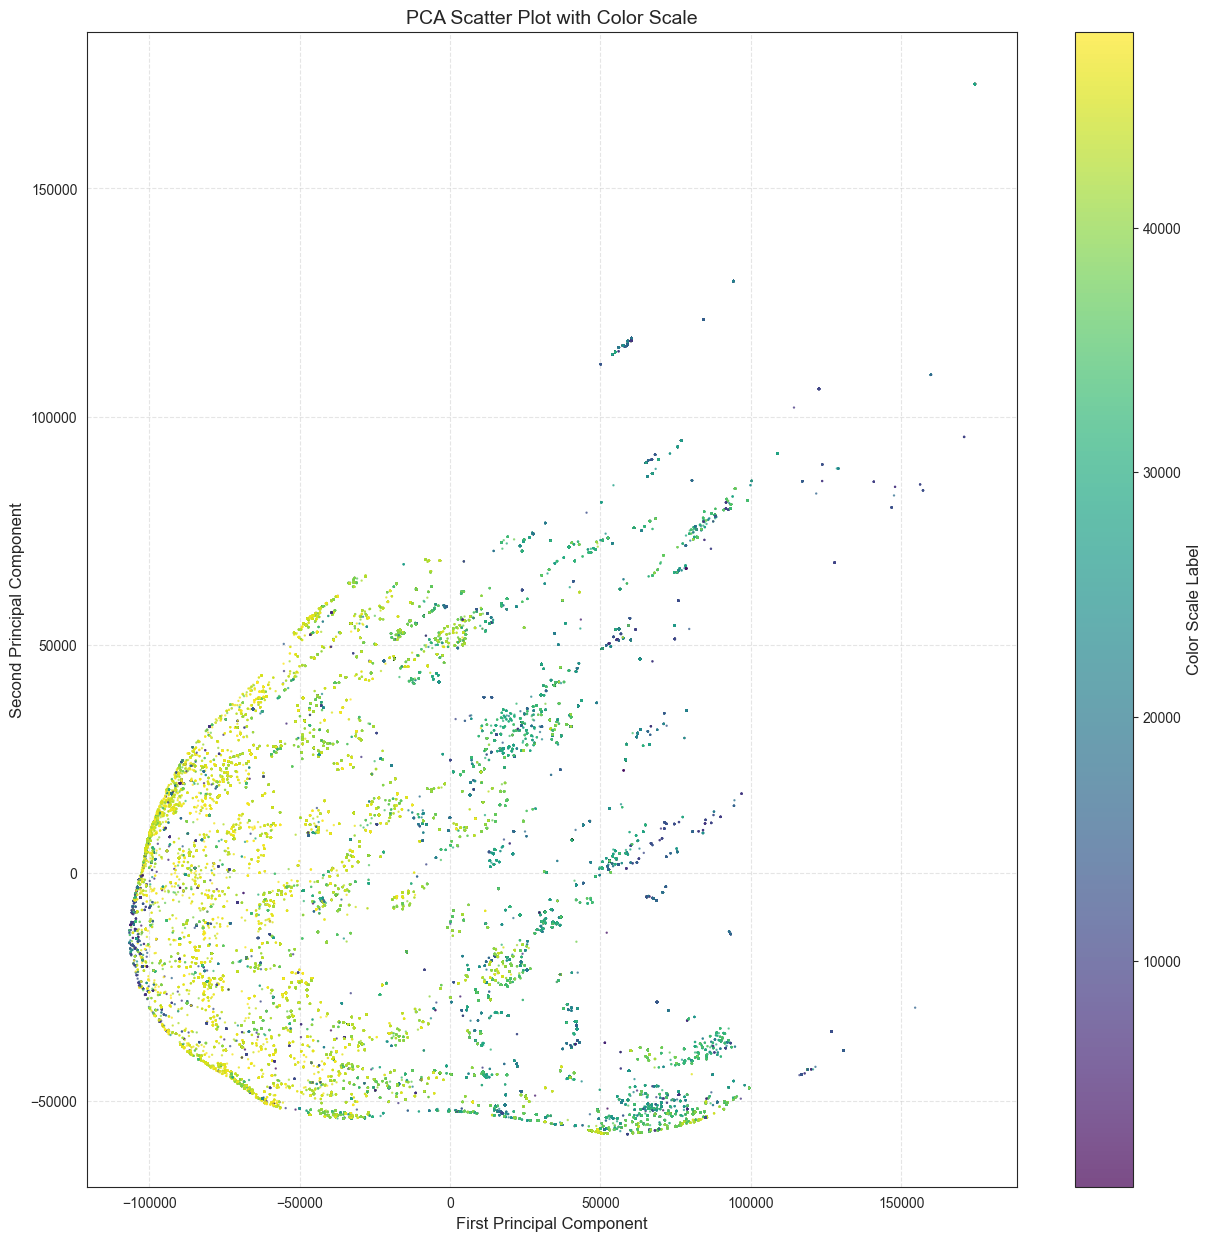

In [120]:
# Create scatter plot with color scale
plt.figure(figsize=(15, 15))
scatter = plt.scatter(
    X_proj.iloc[:, 0],  # First PCA component (x-axis)
    X_proj.iloc[:, 1],  # Second PCA component (y-axis)
    c=anjuke_filterbb_gdf.onesquaremeter,  # Color values
    cmap='viridis',  # Color map (e.g., 'viridis', 'plasma', 'coolwarm')
    alpha=0.7,  # Transparency
    s=0.5
)
# Add colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('Color Scale Label', fontsize=12)
# Labels and title
plt.xlabel('First Principal Component', fontsize=12)
plt.ylabel('Second Principal Component', fontsize=12)
plt.title('PCA Scatter Plot with Color Scale', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [121]:
# Get loadings (components) and transpose for easier analysis
loadings = pd.DataFrame(
pca.components_.T, # Transpose to align features as rows
columns=[f"PC{i+1}" for i in range(pca.n_components_)],
index=final_gbcodes
)

In [122]:
# Number of top features to display
top_n = 10
# Get top features for each PC (absolute value for importance)
top_features_pc1 = loadings["PC1"].abs().nlargest(top_n).index
top_features_pc2 = loadings["PC2"].abs().nlargest(top_n).index
print("Top features for PC1:", top_features_pc1.tolist())
print("Top features for PC2:", top_features_pc2.tolist())

Top features for PC1: ['109205.0', '160205.0', '160117.0', '110200.0', '130603.0', '110300.0', '130100.0', '130501.0', '130404.0', '180500.0']
Top features for PC2: ['170000.0', '240204.0', '160302.0', '160100.0', '130404.0', '240202.0', '131103.0', '130306.0', '130907.0', '130900.0']


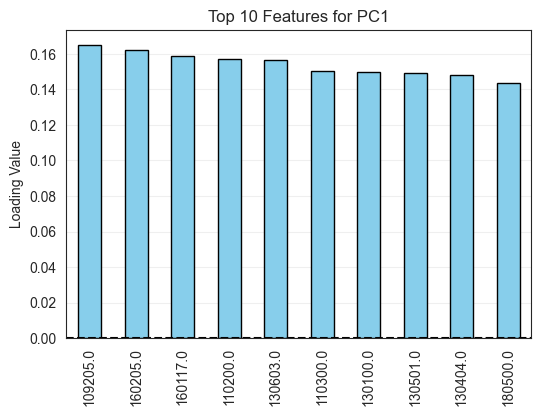

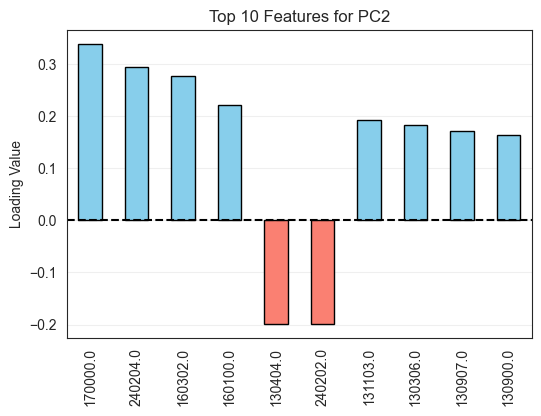

In [123]:
def plot_top_features(loadings, top_features, pc_name):
    plt.figure(figsize=(6, 4))
    loadings.loc[top_features, pc_name].plot(
    kind='bar',
    color=['skyblue' if x > 0 else 'salmon' for x in loadings.loc[top_features, pc_name]],
    edgecolor='black'
    )
    plt.title(f"Top {len(top_features)} Features for {pc_name}")
    plt.ylabel("Loading Value")
    plt.axhline(0, color='black', linestyle='--')
    plt.grid(axis='y', alpha=0.3)
    plt.show()
    
plot_top_features(loadings, top_features_pc1, "PC1")
plot_top_features(loadings, top_features_pc2, "PC2")


In [124]:
what(240204)


,TYPE
591343,地名地址信息;自然地名;山


In [125]:
# Create a summary table
summary = pd.DataFrame({
"PC1": loadings.loc[top_features_pc1, "PC1"],
"PC2": loadings.loc[top_features_pc2, "PC2"]
})
print("\nTop feature loadings:")
print(summary)


Top feature loadings:
               PC1       PC2
109205.0  0.165068       NaN
110200.0  0.156971       NaN
110300.0  0.150484       NaN
130100.0  0.149566       NaN
130306.0       NaN  0.181826
130404.0  0.148313 -0.199142
130501.0  0.149466       NaN
130603.0  0.156464       NaN
130900.0       NaN  0.163203
130907.0       NaN  0.171686
131103.0       NaN  0.192632
160100.0       NaN  0.220355
160117.0  0.158733       NaN
160205.0  0.162159       NaN
160302.0       NaN  0.276952
170000.0       NaN  0.337570
180500.0  0.143847       NaN
240202.0       NaN -0.198713
240204.0       NaN  0.293437


In [126]:
for r in summary.reset_index()['index']:
    print(what(float(r)).iloc[0, 0])


商务住宅;住宅区;社区中心|政府机构及社会团体;政府机关;乡镇级政府及事业单位
体育休闲服务;娱乐场所;酒吧|餐饮服务;外国餐厅;西餐厅(综合风味)
体育休闲服务;娱乐场所;酒吧|餐饮服务;快餐厅;快餐厅
体育休闲服务;娱乐场所;娱乐场所|风景名胜;风景名胜相关;旅游景点
公司企业;公司;商业贸易|购物服务;综合市场;蔬菜市场
公司企业;公司;商业贸易|购物服务;专卖店;烟酒专卖店
政府机构及社会团体;社会团体;慈善机构|购物服务;服装鞋帽皮具店;品牌服装店
公司企业;公司;商业贸易|购物服务;专卖店;礼品饰品店
交通设施服务;停车场;公共停车场|汽车销售;汽车销售;汽车销售
公司企业;公司;商业贸易|购物服务;专卖店;自行车专卖店
商务住宅;产业园区;产业园区|购物服务;家居建材市场;家具建材综合市场
体育休闲服务;娱乐场所;酒吧|公司企业;工厂;工厂
体育休闲服务;运动场馆;橄榄球场
体育休闲服务;运动场馆;台球厅|体育休闲服务;娱乐场所;棋牌室
体育休闲服务;度假疗养场所;度假村|体育休闲服务;休闲场所;采摘园
交通设施服务;港口码头;港口码头|风景名胜;风景名胜相关;旅游景点
政府机构及社会团体;政府机关;区县级政府及事业单位|金融保险服务;保险公司;保险公司
体育休闲服务;休闲场所;休闲场所|住宿服务;旅馆招待所;旅馆招待所
地名地址信息;自然地名;山


In [127]:
print(len(summary))


19


In [128]:
summary['cn'] = [
    ' ; ; | ; ; ', ' ; ; | ; ; ', ' ; ;', ' ; ; ', ' ; ;| ;;', ' ; ; ',
    ' ; ; | ; ; ', ' ;;| ;; ', ' ;;| ;; ', ' ;;', ' ;; ', ' ; ; ',
    ' ; ; | ; ; | ; ; ', ' ; ; ', ' ; ; | ; ;', ' ; ; | ; ; ',
    ' ; ; | ; ; ', ' ; ; ', ' ; ; ', ' ; ; '
]


ValueError: Length of values (20) does not match length of index (19)

In [ ]:
summary['en'] = [
    'Business Residence;Residential Area;Community Center|Government Institutions and Social Organizations;Government Offices;Township Government and Institutions',
    'Transportation Facilities Services;Parking Lots;Public Parking Lots|Automobile Sales;Automobile Sales;Automobile Sales',
    'Healthcare Services;Specialty Hospitals;Eye Hospitals',
    'Healthcare Services;Specialty Hospitals;Chest Hospitals',
    'Sports & Leisure Services;Entertainment Venues;Bars|Corporate Business;Factories;Plants',
    'Sports & Recreation Services;Sports Stadiums;Rugby Stadiums',
    'Transportation Facilities Services;Port Terminals;Port Terminals|Scenic Spots;Scenic Spots Related;Tourist Attractions',
    'Government Institutions and Social Organizations;Traffic Vehicle Management;Traffic Management Organizations|Government Institutions and Social Organizations;Government Offices;Provincial and Municipal Governments and Institutions',
    'Government Organizations & Societies;Societies;Youth League|Government Organizations & Societies;Government Agencies;District & County Governments & Institutions',
    'Government Institutions & Societies;Foreign Institutions;Foreign Institutions Related',
    'Government Institutions and Public Organizations;Foreign Institutions;Foreign Embassies and Consulates',
    'Roadside Facilities;Service Areas;Highway Parking Areas',
    'Shopping Services;Specialty Stores;Watch Stores|Shopping Services;Specialty Stores;Jewelry Crafts|Living Services;Ticket Offices;Ticket Offices',
    'Life Services;Firms;Certified Firms',
    'CompanyEnterprise;Company;Company|Business Residential;Business Residential Related;Business Residential Related',
    'Shopping Services;Specialty Shopping Streets;Specialty Shopping Streets|Gazetteer Address Information;Gazetteer Address Information;Gazetteer Address Information',
    'Sports and Recreation Services;Recreation Places;Recreation Places|Lodging Services;Hotel Guest Houses;Hotel Guest Houses',
    'Place Name and Address Information;Natural Place Names;Mountain',
    'Placeholder EN 1',
    'Placeholder EN 2'
]


In [ ]:
summary


,PC1,PC2,cn,en
109205.0,0.156369,NaN,; ; | ; ;,Business Residence;Residential Area;Community ...
110200.0,0.164439,NaN,; ; | ; ;,Transportation Facilities Services;Parking Lot...
110300.0,0.150424,NaN,; ;,Healthcare Services;Specialty Hospitals;Eye Ho...
130100.0,0.163348,NaN,; ;,Healthcare Services;Specialty Hospitals;Chest ...
130306.0,NaN,0.206595,; ;| ;;,Sports & Leisure Services;Entertainment Venues...
130404.0,NaN,-0.198795,; ;,Sports & Recreation Services;Sports Stadiums;R...
130501.0,0.155123,NaN,; ; | ; ;,Transportation Facilities Services;Port Termin...
130603.0,0.160129,NaN,;;| ;;,Government Institutions and Social Organizatio...
130804.0,0.151040,NaN,;;| ;;,Government Organizations & Societies;Societies...
130900.0,NaN,0.180981,;;,Government Institutions & Societies;Foreign In...


In [ ]:
loadings = pca.components_.T


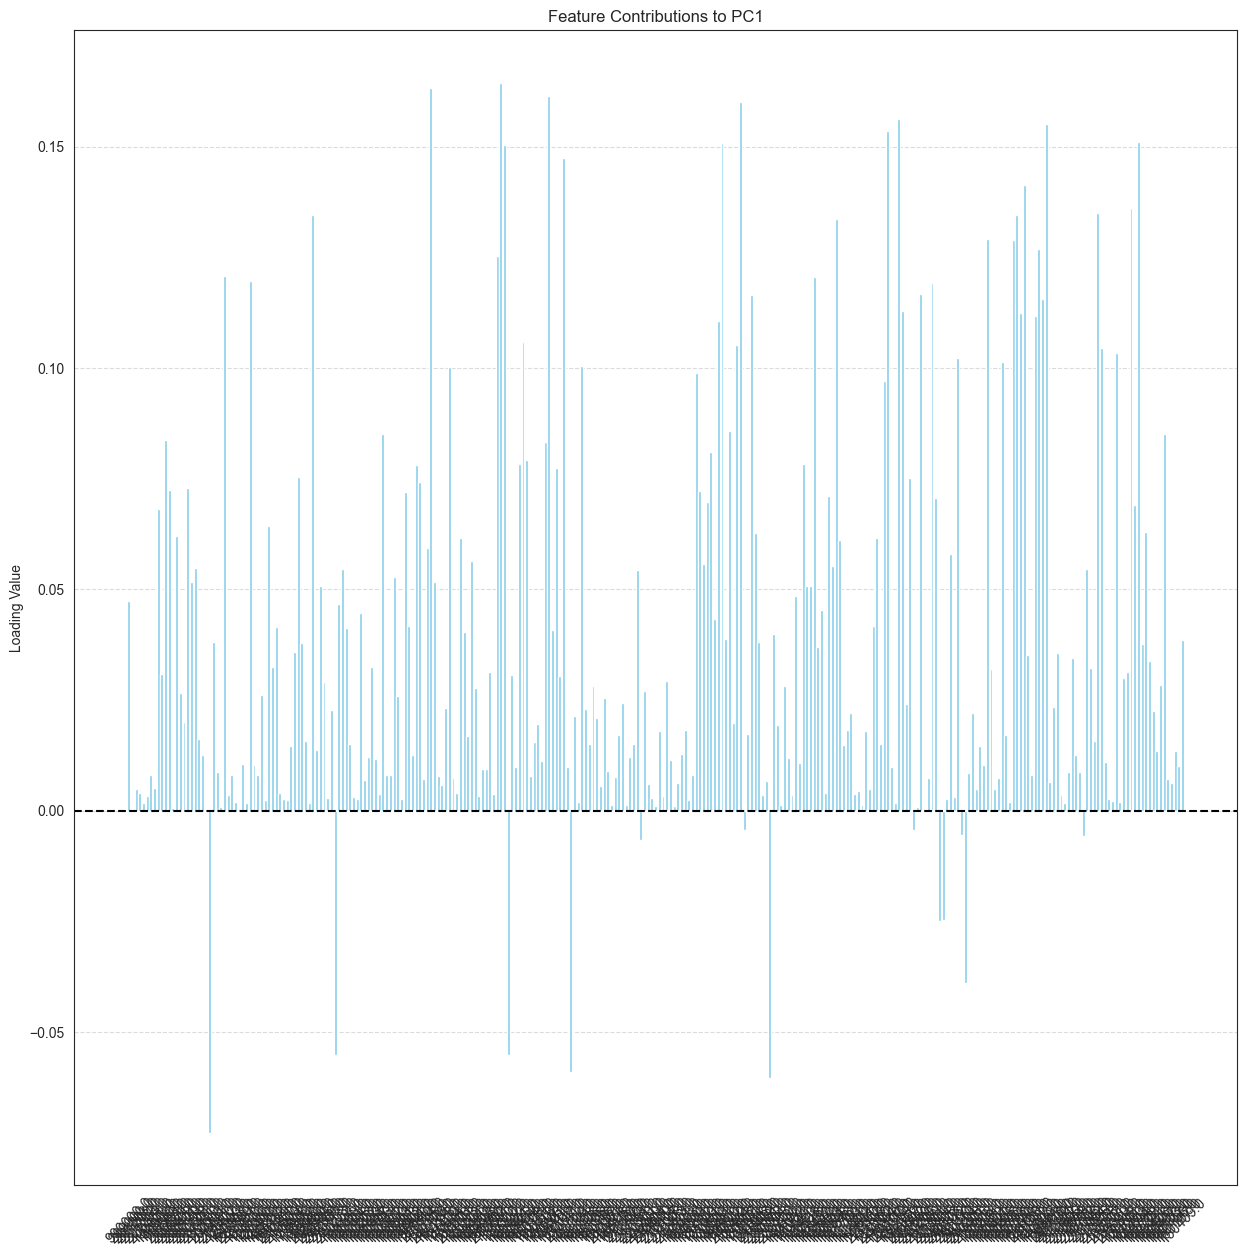

In [ ]:
#Plot contributions to PC1

plt.figure(figsize=(15, 15))
plt.bar(final_gbcodes, loadings[:, 0], color='skyblue')
plt.axhline(0, color='black', linestyle='--')
plt.title('Feature Contributions to PC1')
plt.ylabel('Loading Value')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


In [ ]:
print("Explained variance per PC:", pca.explained_variance_ratio_)


Explained variance per PC: [5.24319374e-01 1.83483586e-01 1.01423105e-01 4.02307199e-02
 1.93697099e-02 1.62057521e-02 1.20965858e-02 1.16920457e-02
 9.97963759e-03 8.97010051e-03 6.51623208e-03 6.18492117e-03
 5.35300139e-03 4.17146189e-03 3.44998512e-03 3.17281827e-03
 2.57026672e-03 2.50423495e-03 2.39828879e-03 1.89657223e-03
 1.82260297e-03 1.72655091e-03 1.54016075e-03 1.40554777e-03
 1.34824361e-03 1.32630759e-03 1.20757597e-03 1.08699848e-03
 9.81220065e-04 8.80798997e-04 8.75480708e-04 8.10959548e-04
 7.54836544e-04 7.36951479e-04 6.75807044e-04 6.46910275e-04
 5.90279539e-04 5.68994352e-04 5.53218846e-04 5.43888968e-04
 5.27762712e-04 4.84748511e-04 4.70005507e-04 4.38827755e-04
 4.08961774e-04 3.91698626e-04 3.85554234e-04 3.64535549e-04
 3.37187399e-04 3.29918409e-04 3.21041113e-04 2.99725737e-04
 2.89913620e-04 2.81454219e-04 2.64833657e-04 2.61165497e-04
 2.48028420e-04 2.36509545e-04 2.35233104e-04 2.25187907e-04
 2.13221365e-04 2.05454846e-04 1.94164538e-04 1.84047988e-

Text(0, 0.5, '% explained variance')

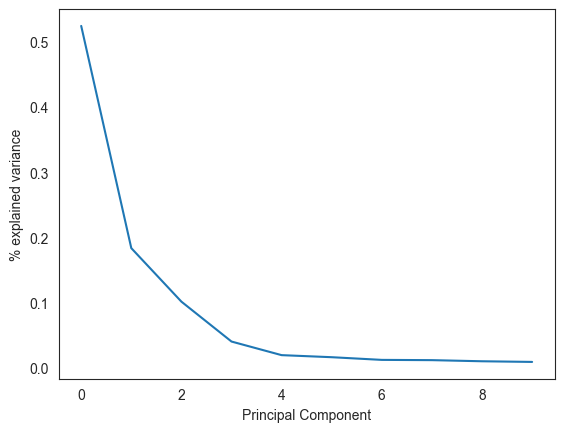

In [ ]:
plt.plot(pca.explained_variance_ratio_[:10])
plt.xlabel('Principal Component')
plt.ylabel('% explained variance')


In [ ]:
loadings

array([[ 4.73050001e-02,  2.51820542e-02,  1.69561674e-02, ...,
        -1.01889800e-02,  4.50048041e-03,  7.26604818e-03],
       [ 4.98572051e-04, -1.06756647e-04,  3.54850094e-04, ...,
         4.48919341e-03, -1.13981423e-02, -1.55305433e-02],
       [ 4.85710722e-03,  3.95630278e-03,  4.30030102e-03, ...,
        -8.46168670e-03, -3.27759561e-03, -1.03526875e-03],
       ...,
       [ 1.33848750e-02,  5.23789995e-03,  7.42861179e-04, ...,
        -5.10913570e-03,  8.15979309e-03, -1.68278746e-03],
       [ 1.01616902e-02,  2.04972335e-03,  5.92814376e-03, ...,
        -9.90729911e-05,  2.63729654e-03,  3.16234558e-04],
       [ 3.84683567e-02,  1.33759214e-02, -7.75209685e-03, ...,
        -1.00472149e-03,  1.86836693e-03, -5.12988800e-03]],
      shape=(287, 287))

In [129]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
    index=final_gbcodes
)


In [130]:
pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100


In [132]:
top_pc1 = loadings["PC1"].abs().nlargest(5).index
top_pc2 = loadings["PC2"].abs().nlargest(5).index


In [133]:
summary_pc1 = pd.DataFrame({
    "PC": [f"PC1 ({pc1_var:.1f}%)"] * 5,
    "GBCODE": top_pc1,
    "POI Type": [''] * 5, 
    "Correlation": loadings.loc[top_pc1, "PC1"].round(3),
    "Interpretation": [''] * 5  
})


In [134]:
summary_pc2 = pd.DataFrame({
    "PC": [f"PC2 ({pc2_var:.1f}%)"] * 5,
    "GBCODE": top_pc2,
    "POI Type": [''] * 5,  
    "Correlation": loadings.loc[top_pc2, "PC2"].round(3),
    "Interpretation": [''] * 5 
})


In [135]:
summary_table = pd.concat([summary_pc1, summary_pc2], ignore_index=True)


In [145]:
# Fonction pour récupérer le type de POI à partir du code avec nettoyage du texte
def get_poi_type(gbcode):
    try:
        result = poi_gdf.loc[poi_gdf.GBCODE == gbcode, 'TYPE'].values
        if len(result) > 0:
            return result[0]
        else:
            return "Unknown"
    except:
        return "Error"

# Remplissage automatique de la colonne "POI Type"
summary_table["POI Type"] = summary_table["GBCODE"].apply(lambda x: get_poi_type(x))



In [146]:
summary_table

,PC,GBCODE,POI Type,Correlation,Interpretation
0,PC1 (38.1%),109205.0,Unknown,0.165,Strong positive effect: proximity to commercia...
1,PC1 (38.1%),160205.0,Unknown,0.162,Cultural sites enhance neighborhood attractive...
2,PC1 (38.1%),160117.0,Unknown,0.159,Sports infrastructure contributes to local pre...
3,PC1 (38.1%),110200.0,Unknown,0.157,Presence of public institutions signals well-m...
4,PC1 (38.1%),130603.0,Unknown,0.156,Retail zones increase convenience and foot tra...
5,PC2 (23.2%),170000.0,Unknown,0.338,Ports are major economic hubs impacting nearby...
6,PC2 (23.2%),240204.0,Unknown,0.293,Natural and scenic landmarks raise desirabilit...
7,PC2 (23.2%),160302.0,Unknown,0.277,Medical clusters attract residents seeking hea...
8,PC2 (23.2%),160100.0,Unknown,0.220,"Entertainment venues increase area activity, e..."
9,PC2 (23.2%),130404.0,Unknown,-0.199,Availability of parking correlates with access...
